# TP1 — Statistiques sur des données météo avec NumPy
**Python Avancé · Licence 3 IA · ISM École d'ingénieurs · Enseignant : Elias BADJI**

**Noms:** Adja Fatou Kiné NGOM et Seynabou SALL**


# chargement des fichiers


In [12]:
# ============================================
# ÉTAPE 1 : Créer le dossier data/ et uploader les 4 CSV
# ============================================
import os
from google.colab import files

# 1. Créer le dossier "data" (s'il n'existe pas déjà)
os.makedirs("data", exist_ok=True)
print("✅ Dossier data/ prêt")

# 2. Ouvrir la fenêtre pour choisir les fichiers
print("📂 Choisis tes 4 fichiers CSV...")
uploaded = files.upload()

# 3. Ranger automatiquement les fichiers dans data/
for nom in uploaded:
    os.rename(nom, os.path.join("data", nom))

# 4. Afficher le résultat
print("\n📁 Contenu de data/ :")
for f in os.listdir("data"):
    print("   -", f)

✅ Dossier data/ prêt
📂 Choisis tes 4 fichiers CSV...


Saving buts.csv to buts.csv
Saving equipes.csv to equipes.csv
Saving joueurs.csv to joueurs.csv
Saving matchs.csv to matchs.csv

📁 Contenu de data/ :
   - matchs.csv
   - buts.csv
   - joueurs.csv
   - equipes.csv


In [17]:
import os
import pandas as pd
import numpy as np

# 1. Vérifier que les 4 fichiers sont bien présents
for f in ["equipes.csv", "matchs.csv", "joueurs.csv", "buts.csv"]:
    chemin = os.path.join("data", f)
    print(chemin, "->", "OK" if os.path.exists(chemin) else "MANQUANT")

print()

# 2. Charger les 4 fichiers
equipes = pd.read_csv("data/equipes.csv")
matchs  = pd.read_csv("data/matchs.csv", parse_dates=["date"])
joueurs = pd.read_csv("data/joueurs.csv")
buts    = pd.read_csv("data/buts.csv")

print("✅ Chargement terminé\n")
print("equipes :", equipes.shape)
print("matchs  :", matchs.shape)
print("joueurs :", joueurs.shape)
print("buts    :", buts.shape)

data/equipes.csv -> OK
data/matchs.csv -> OK
data/joueurs.csv -> OK
data/buts.csv -> OK

✅ Chargement terminé

equipes : (20, 8)
matchs  : (1145, 13)
joueurs : (1688, 15)
buts    : (2660, 8)


#PARTIE 1 — Chargement et diagnostic

Question 1.2 — Forme et types des DataFrames


In [18]:
for nom, df in [("equipes", equipes), ("matchs", matchs),
                ("joueurs", joueurs), ("buts", buts)]:
    print("=" * 50)
    print(nom, ":", df.shape)
    df.info()
    print()

equipes : (20, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   equipe_id             20 non-null     object
 1   nom                   20 non-null     object
 2   ville                 20 non-null     object
 3   region                20 non-null     object
 4   annee_creation        20 non-null     int64 
 5   stade                 20 non-null     object
 6   capacite_stade        20 non-null     int64 
 7   budget_millions_fcfa  20 non-null     int64 
dtypes: int64(3), object(5)
memory usage: 1.4+ KB

matchs : (1145, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1145 entries, 0 to 1144
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   match_id            1145 non-null   object        
 1   saison              1145 non-

Question 1.3 — Problème de type sur salaire


In [19]:
print("Type actuel :", joueurs["salaire_mensuel_fcfa"].dtype)

# Chercher les valeurs qui contiennent un espace
mask = joueurs["salaire_mensuel_fcfa"].astype(str).str.contains(" ", na=False)
print("\nNombre de valeurs avec espace :", mask.sum())
print("\nExemples :")
print(joueurs.loc[mask, "salaire_mensuel_fcfa"].head(10).tolist())

Type actuel : object

Nombre de valeurs avec espace : 40

Exemples :
['450 000', '510 000', '450 000', '350 000', '430 000', '390 000', '210 000', '260 000', '470 000', '670 000']


Question 1.4 — Valeurs manquantes


interpretation: Les valeurs manquantes concernent surtout spectateurs (matchs), salaire_mensuel_fcfa et date_naissance (joueurs). Dans buts, les passeur_id manquants ne sont pas une erreur : cela veut dire que le but a été marqué sans passe décisive (penalty, coup franc direct, ou action individuelle).

In [20]:
for nom, df in [("equipes", equipes), ("matchs", matchs),
                ("joueurs", joueurs), ("buts", buts)]:
    print("=" * 40, nom)
    print(df.isna().sum())
    print()

======================================== equipes
equipe_id               0
nom                     0
ville                   0
region                  0
annee_creation          0
stade                   0
capacite_stade          0
budget_millions_fcfa    0
dtype: int64

======================================== matchs
match_id               0
saison                 0
journee                0
date                   0
heure                  0
equipe_dom_id          0
equipe_ext_id          0
buts_dom               0
buts_ext               0
tirs_dom               0
tirs_ext               0
possession_dom_pct     0
spectateurs           18
dtype: int64

======================================== joueurs
saison                   0
joueur_id                0
prenom                   0
nom                      0
equipe_id                0
poste                    0
date_naissance          10
nationalite              0
salaire_mensuel_fcfa    15
matchs_joues             0
minutes_jouees         

## Partie 1 — Mise en place et chargement des données (2 pts)

In [14]:
# On crée le dossier "data"
import os
os.makedirs("data", exist_ok=True)

# On ouvre la fenêtre pour choisir le fichier
from google.colab import files
fichier = files.upload()

# On déplace le fichier dans le dossier "data"
for nom in fichier.keys():
    os.replace(nom, "data/" + nom)

Saving buts.csv to buts.csv
Saving equipes.csv to equipes.csv
Saving joueurs.csv to joueurs.csv
Saving matchs.csv to matchs.csv


In [15]:
import numpy as np
print("Version de NumPy :", np.__version__)

Version de NumPy : 2.1.3


In [16]:
d = np.genfromtxt("data/meteo_dakar_2025.csv", delimiter=",",
                  names=True, dtype=None, encoding="utf-8")
print(d.dtype.names)
print(d[:3])

FileNotFoundError: data/meteo_dakar_2025.csv not found.

In [ ]:
dates = d["date"]
mois  = d["mois"]
jour  = d["jour"]
tmax  = d["temp_max_c"]
tmin  = d["temp_min_c"]
hum   = d["humidite_pct"]
pluie = d["pluie_mm"]
vent  = d["vent_kmh"]

NOMS_MOIS = np.array(["Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
                      "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])

In [ ]:
print("d.dtype    :", d.dtype)
print("tmax.dtype :", tmax.dtype)

d.dtype    : [('date', '<U10'), ('mois', '<i8'), ('jour', '<i8'), ('temp_max_c', '<f8'), ('temp_min_c', '<f8'), ('humidite_pct', '<i8'), ('pluie_mm', '<f8'), ('vent_kmh', '<i8')]
tmax.dtype : float64


**Interprétation 1.5.** `d` est un tableau structuré : chaque ligne contient plusieurs colonnes de types différents (du texte pour la date, des entiers, des nombres décimaux), et on les appelle par leur nom. `tmax` est un tableau NumPy classique : il ne contient qu'un seul type de données (des décimaux `float64`), ce qui permet de faire des calculs rapidement.

## Partie 2 — Exploration (3 pts)

In [ ]:
print("tmax  :", tmax.shape,  tmax.ndim,  tmax.dtype)
print("mois  :", mois.shape,  mois.ndim,  mois.dtype)
print("dates :", dates.shape, dates.ndim, dates.dtype)

tmax  : (365,) 1 float64
mois  : (365,) 1 int64
dates : (365,) 1 <U10


**Interprétation 2.1.** Les trois tableaux ont une seule dimension et 365 éléments, un par jour de l'année. Ils ne diffèrent que par leur type : `tmax` contient des nombres décimaux (`float64`), `mois` des nombres entiers (`int64`) et `dates` du texte de 10 caractères (`<U10`, par exemple « 2025-01-01 »).

In [ ]:
print("tmax min :", tmax.min())
print("tmax max :", tmax.max())
print("moyenne annuelle tmax :", round(tmax.mean(), 2))
print("moyenne annuelle tmin :", round(tmin.mean(), 2))

tmax min : 22.4
tmax max : 34.1
moyenne annuelle tmax : 28.01
moyenne annuelle tmin : 21.77


**Interprétation 2.2.** En 2025, la température maximale du jour varie de 22,4 °C à 34,1 °C. En moyenne, il fait 28,01 °C la journée (tmax) et 21,77 °C la nuit (tmin), soit environ 6 °C de différence. Le climat de Dakar est donc chaud toute l'année.

In [ ]:
print("1re semaine de janvier :", tmax[:7])
print("10 derniers jours       :", tmax[-10:])

m15 = dates == "2025-03-15"
print("15 mars :", dates[m15], tmax[m15], tmin[m15], pluie[m15])

print("1 jour sur 7 :", tmax[::7])

1re semaine de janvier : [27.1 26.7 26.  26.  27.9 27.1 24.6]
10 derniers jours       : [26.9 26.  26.1 26.  26.7 26.2 27.1 26.9 26.4 27. ]
15 mars : ['2025-03-15'] [26.4] [19.1] [0.]
1 jour sur 7 : [27.1 26.1 24.8 25.  23.5 24.5 25.6 27.2 28.6 25.9 25.2 27.4 26.8 26.3
 25.  27.4 29.5 28.7 26.5 26.4 25.7 27.8 25.5 30.8 30.4 28.3 28.8 28.9
 27.5 30.1 29.2 30.9 30.1 29.3 28.7 28.2 30.8 32.8 30.  33.1 29.3 31.6
 30.7 32.2 28.5 28.7 28.8 26.4 25.3 27.1 28.6 26.1 27. ]


**Interprétation 2.3.** Le découpage (`[:7]`, `[-10:]`, `[::7]`) sélectionne par position, alors que le masque booléen sélectionne par condition (ici la date). Le 15 mars est un jour sec (0 mm de pluie).

In [ ]:
print("Journée la plus chaude :", dates[tmax.argmax()], "->", tmax.max(), "°C")
print("Nuit la plus fraîche    :", dates[tmin.argmin()], "->", tmin.min(), "°C")

Journée la plus chaude : 2025-09-18 -> 34.1 °C
Nuit la plus fraîche    : 2025-02-07 -> 16.1 °C


**Interprétation 2.4.** La journée la plus chaude est le 18 septembre 2025 (34,1 °C) et la nuit la plus fraîche le 7 février 2025 : le maximum tombe en fin de saison des pluies, le minimum en pleine saison sèche.

## Partie 3 — Statistiques mensuelles (4 pts)

In [ ]:
print("Moyenne de tmax en août :", round(tmax[mois == 8].mean(), 2))

Moyenne de tmax en août : 30.22


**Interprétation 3.1.** La température maximale moyenne d'août est de 30,22 °C.

In [ ]:
nb_jours = np.bincount(mois - 1)                 # jours par mois
somme    = np.bincount(mois - 1, weights=tmax)   # somme de tmax par mois
moy_tmax = somme / nb_jours

print("Jours par mois :", nb_jours)
lignes = np.char.add(np.char.add(NOMS_MOIS, " : "), np.char.mod("%.2f", moy_tmax))
print(*lignes, sep="\n")

Jours par mois : [31 28 31 30 31 30 31 31 30 31 30 31]
Jan : 25.29
Fév : 25.85
Mar : 26.36
Avr : 26.57
Mai : 26.64
Juin : 29.23
Juil : 28.47
Août : 30.22
Sep : 30.88
Oct : 31.20
Nov : 28.48
Déc : 26.87


**Interprétation 3.2.** `np.bincount` utilise la valeur comme indice de case, et les indices commencent à 0 : sans `- 1`, on obtiendrait 13 cases avec une case 0 vide et un décalage d'un mois par rapport à `NOMS_MOIS`. Avec `mois - 1`, janvier (1) → case 0 … décembre (12) → case 11. Les moyennes montent de 25,29 °C (janvier) à 31,20 °C (octobre).

In [ ]:
print("Mois le plus chaud :", NOMS_MOIS[moy_tmax.argmax()], round(moy_tmax.max(), 2))
print("Mois le plus frais :", NOMS_MOIS[moy_tmax.argmin()], round(moy_tmax.min(), 2))

Mois le plus chaud : Oct 31.2
Mois le plus frais : Jan 25.29


**Interprétation 3.3.** Octobre est le mois le plus chaud en moyenne (31,20 °C) et janvier le plus frais (25,29 °C). Le pic est décalé par rapport à l'été : il suit la saison des pluies.

In [ ]:
amplitude = tmax - tmin
print("Amplitude maximale :", round(amplitude.max(), 2), "le", dates[amplitude.argmax()])

moy_ampl = np.bincount(mois - 1, weights=amplitude) / nb_jours
lignes = np.char.add(np.char.add(NOMS_MOIS, " : "), np.char.mod("%.2f", moy_ampl))
print(*lignes, sep="\n")
print("Mois d'amplitude moyenne minimale :", NOMS_MOIS[moy_ampl.argmin()])

Amplitude maximale : 9.7 le 2025-02-26
Jan : 7.10
Fév : 7.97
Mar : 7.17
Avr : 6.89
Mai : 5.85
Juin : 5.46
Juil : 4.33
Août : 4.68
Sep : 5.62
Oct : 6.19
Nov : 6.62
Déc : 7.23
Mois d'amplitude moyenne minimale : Juil


**Interprétation 3.4.** L'amplitude moyenne est la plus faible en juillet (≈ 4,3 °C), donc en saison des pluies, et la plus forte en saison sèche (≈ 8 °C en février). L'humidité et la nébulosité de la saison humide limitent le refroidissement nocturne.

In [ ]:
cumul = np.bincount(mois - 1, weights=pluie)
total = cumul.sum()
lignes = np.char.add(np.char.add(NOMS_MOIS, " : "), np.char.mod("%.1f mm", cumul))
print(*lignes, sep="\n")
print("Total annuel :", round(total, 1), "mm")
print("Part d'août  :", round(cumul[7] / total * 100, 1), "%")
print("Mois totalement secs :", (cumul == 0).sum())

Jan : 0.0 mm
Fév : 0.0 mm
Mar : 0.0 mm
Avr : 0.0 mm
Mai : 0.8 mm
Juin : 13.5 mm
Juil : 71.4 mm
Août : 275.2 mm
Sep : 70.3 mm
Oct : 22.6 mm
Nov : 9.4 mm
Déc : 0.0 mm
Total annuel : 463.2 mm
Part d'août  : 59.4 %
Mois totalement secs : 5


**Interprétation 3.5.** Il tombe 463,2 mm sur l'année, dont environ 59,4 % en août. Cinq mois sont totalement secs (janvier à avril et décembre) : la pluie est très concentrée sur la saison de juin à octobre.

## Partie 4 — Masques booléens (4 pts)

In [ ]:
chaud30 = tmax > 30
print("Jours > 30 °C sur l'année :", chaud30.sum())
par_mois = np.bincount(mois - 1, weights=chaud30).astype(int)
lignes = np.char.add(np.char.add(NOMS_MOIS, " : "), par_mois.astype(str))
print(*lignes, sep="\n")

Jours > 30 °C sur l'année : 82
Jan : 0
Fév : 0
Mar : 0
Avr : 0
Mai : 0
Juin : 12
Juil : 3
Août : 16
Sep : 21
Oct : 24
Nov : 6
Déc : 0


**Interprétation 4.1.** 82 jours dépassent 30 °C, presque tous entre juin et octobre (maximum en octobre avec 24 jours) ; il n'y en a aucun de janvier à mai ni en décembre.

In [ ]:
print("Jours de pluie :", (pluie > 0).sum(), "-> tmax moyenne :", round(tmax[pluie > 0].mean(), 2))
print("Jours secs     :", (pluie == 0).sum(), "-> tmax moyenne :", round(tmax[pluie == 0].mean(), 2))

Jours de pluie : 53 -> tmax moyenne : 29.02
Jours secs     : 312 -> tmax moyenne : 27.84


**Interprétation 4.2.** Les jours de pluie sont un peu plus chauds (29,02 °C contre 27,84 °C). Ce n'est pas la pluie qui réchauffe : elle tombe en été/automne, saison naturellement plus chaude, et la saison est le facteur commun (effet de saisonnalité).

In [ ]:
masque = (hum > 85) & (vent > 15)
print("Nombre de jours humides ET venteux :", masque.sum())
print(dates[masque])

Nombre de jours humides ET venteux : 11
['2025-06-04' '2025-06-17' '2025-06-25' '2025-07-22' '2025-08-02'
 '2025-08-12' '2025-08-28' '2025-08-29' '2025-09-04' '2025-09-16'
 '2025-09-24']


**Interprétation 4.3.** Seuls 11 jours cumulent humidité > 85 % et vent > 15 km/h, tous entre juin et septembre : la combinaison est rare et liée à la saison des pluies.

In [ ]:
# (a) avec copie
tmax_ecretee = tmax.copy()
tmax_ecretee[tmax_ecretee > 31] = 31
print("Avec copy    -> max écrêté :", tmax_ecretee.max(), "| max de tmax :", tmax.max())

# (b) sans copie
tmax_ecretee = tmax
tmax_ecretee[tmax_ecretee > 31] = 31
print("Sans copy    -> max écrêté :", tmax_ecretee.max(), "| max de tmax :", tmax.max())

Avec copy    -> max écrêté : 31.0 | max de tmax : 34.1
Sans copy    -> max écrêté : 31.0 | max de tmax : 31.0


**Interprétation 4.4.** Avec `.copy()`, on obtient un nouveau tableau indépendant : `tmax` garde son maximum de 34,1 °C. Sans `.copy()`, `tmax_ecretee = tmax` ne crée pas de tableau mais un second nom pour le **même** objet en mémoire : modifier l'un modifie l'autre, et `tmax` est corrompu (maximum 31). D'où le rechargement des données.

In [ ]:
# (c) Rechargement des données (tmax est corrompu)
d = np.genfromtxt("data/meteo_dakar_2025.csv", delimiter=",",
                  names=True, dtype=None, encoding="utf-8")
dates = d["date"]; mois = d["mois"]; jour = d["jour"]
tmax = d["temp_max_c"]; tmin = d["temp_min_c"]
hum = d["humidite_pct"]; pluie = d["pluie_mm"]; vent = d["vent_kmh"]
print("tmax rétabli, max =", tmax.max())

tmax rétabli, max = 34.1


In [ ]:
categorie = np.where(tmax > 29, "chaud", np.where(tmax >= 26, "doux", "frais"))
valeurs, effectifs = np.unique(categorie, return_counts=True)
print(valeurs, effectifs)

['chaud' 'doux' 'frais'] [116 175  74]


**Interprétation 4.5.** On compte 116 jours « chaud », 175 « doux » et 74 « frais » (total 365) : la catégorie « doux » domine, les jours chauds représentant environ un tiers de l'année.

## Partie 5 — Transformations et broadcasting (4 pts)

In [ ]:
tmax_f = tmax * 9/5 + 32
print(tmax[:5])
print(tmax_f[:5].round(2))

[27.1 26.7 26.  26.  27.9]
[80.78 80.06 78.8  78.8  82.22]


**Interprétation 5.1.** La formule s'applique d'un coup aux 365 valeurs, sans boucle (ex. 27,1 °C → 80,78 °F).

In [ ]:
X = np.column_stack([tmax, tmin, hum, pluie, vent])
VARIABLES = np.array(["tmax", "tmin", "humidité", "pluie", "vent"])
print(X.shape)

(365, 5)


**Interprétation 5.2.** `X` a pour forme `(365, 5)` : une ligne par jour, une colonne par variable.

In [ ]:
moyennes = X.mean(axis=0)
ecarts   = X.std(axis=0)
print(VARIABLES)
print("Moyennes   :", moyennes.round(2), moyennes.shape)
print("Écarts-types:", ecarts.round(2), ecarts.shape)

['tmax' 'tmin' 'humidité' 'pluie' 'vent']
Moyennes   : [28.01 21.77 74.8   1.27 17.2 ] (5,)
Écarts-types: [2.46 2.93 8.13 6.08 4.67] (5,)


**Interprétation 5.3.** `axis=0` calcule une statistique par colonne (en parcourant les lignes) : le résultat a la forme `(5,)`, une valeur par variable. `axis=1` donnerait 365 valeurs (une par jour) mélangeant des °C, des %, des mm et des km/h : une telle moyenne n'a aucun sens physique.

In [ ]:
Xs = (X - X.mean(axis=0)) / X.std(axis=0)
print("Moyennes   :", Xs.mean(axis=0).round(10))
print("Écarts-types:", Xs.std(axis=0).round(10))

Moyennes   : [ 0. -0.  0. -0.  0.]
Écarts-types: [1. 1. 1. 1. 1.]


**Interprétation 5.4.** Le broadcasting aligne les formes par la droite : `(365, 5)` et `(5,)` → le tableau `(5,)` est vu comme `(1, 5)` puis « étiré » sur les 365 lignes, donc chaque colonne est traitée avec sa propre moyenne et son propre écart-type, sans boucle ni copie. Les colonnes obtenues ont bien une moyenne ≈ 0 et un écart-type = 1.

In [ ]:
corr = np.corrcoef(X, rowvar=False)
print(VARIABLES)
print(corr.round(2))
print("Corrélations avec tmax :", corr[0].round(2))

['tmax' 'tmin' 'humidité' 'pluie' 'vent']
[[ 1.    0.87  0.51  0.11 -0.45]
 [ 0.87  1.    0.73  0.25 -0.54]
 [ 0.51  0.73  1.    0.29 -0.33]
 [ 0.11  0.25  0.29  1.   -0.14]
 [-0.45 -0.54 -0.33 -0.14  1.  ]]
Corrélations avec tmax : [ 1.    0.87  0.51  0.11 -0.45]


**Interprétation 5.5.** La variable la plus corrélée à tmax est tmin (r ≈ 0,87), les deux évoluant avec la saison. Le vent varie en sens inverse (r ≈ −0,45) : les mois chauds sont moins ventés.

In [ ]:
anomalie = tmax - moy_tmax[mois - 1]
i = np.abs(anomalie).argmax()
print("Anomalie la plus forte :", dates[i], round(anomalie[i], 2), "°C")
print("Plus forte anomalie positive :", dates[anomalie.argmax()], round(anomalie.max(), 2))

Anomalie la plus forte : 2025-06-03 -4.73 °C
Plus forte anomalie positive : 2025-11-02 4.32


**Interprétation 5.6.** `moy_tmax[mois - 1]` associe à chaque jour la moyenne de son propre mois. Le 3 juin 2025 a l'anomalie la plus forte en valeur absolue (−4,73 °C, journée très fraîche pour un mois de juin) ; la plus forte anomalie positive est le 2 novembre (+4,32 °C).

In [ ]:
est_chaud = (tmax > 28).astype(int)
bord   = np.concatenate(([0], est_chaud, [0]))
diff   = np.diff(bord)
debuts = np.where(diff == 1)[0]
fins   = np.where(diff == -1)[0]
durees = fins - debuts
k = durees.argmax()
print("Plus longue série :", durees[k], "jours, à partir du", dates[debuts[k]])

Plus longue série : 33 jours, à partir du 2025-09-07


**Interprétation 5.7.** La plus longue série de jours consécutifs au-dessus de 28 °C dure 33 jours, à partir du 7 septembre 2025 : c'est la période de chaleur de fin de saison des pluies.

## Partie 6 — Performance (2 pts)

In [ ]:
def moyennes_boucle(valeurs, mois):
    sommes  = [0.0] * 12
    comptes = [0] * 12
    for v, m in zip(valeurs, mois):
        sommes[m - 1]  += v
        comptes[m - 1] += 1
    return [s / c for s, c in zip(sommes, comptes)]

In [ ]:
print(np.allclose(moyennes_boucle(tmax, mois), moy_tmax))

True


**Interprétation 6.2.** `np.allclose` renvoie `True` : la boucle et `np.bincount` donnent les mêmes 12 moyennes (à la tolérance numérique près).

In [ ]:
rng = np.random.default_rng(0)
mois_grand = rng.integers(1, 13, size=3_650_000)
tmax_grand = rng.normal(28, 3, size=3_650_000)

In [ ]:
%timeit moyennes_boucle(tmax_grand, mois_grand)

2.12 s ± 361 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
%timeit np.bincount(mois_grand - 1, weights=tmax_grand) / np.bincount(mois_grand - 1)

27.2 ms ± 411 µs per loop (mean ± std. dev. of 7 runs, 10 loops each)


**Interprétation 6.3.** Sur ma mesure, la boucle Python prend environ 2,26 s et np.bincount environ 35,5 ms, soit une accélération d'environ ×64 (2260 ÷ 35,5). NumPy est plus rapide car il travaille sur un tableau de type homogène stocké de façon contiguë en mémoire et exécute le calcul en C (vectorisation). La boucle Python, elle, interprète chaque itération et manipule les 3 650 000 valeurs une par une. L'écart s'accentue quand la taille des données augmente.

## Bonus — Moyenne glissante et graphique (+2 pts)

In [ ]:
glissante = np.convolve(tmax, np.ones(7) / 7, mode="valid")
print(glissante.shape)

(359,)


**Interprétation B.1.** En mode `valid`, la fenêtre de 7 jours doit tenir entièrement dans les données : il y a 365 − 7 + 1 = 359 positions possibles, donc 359 valeurs et non 365.

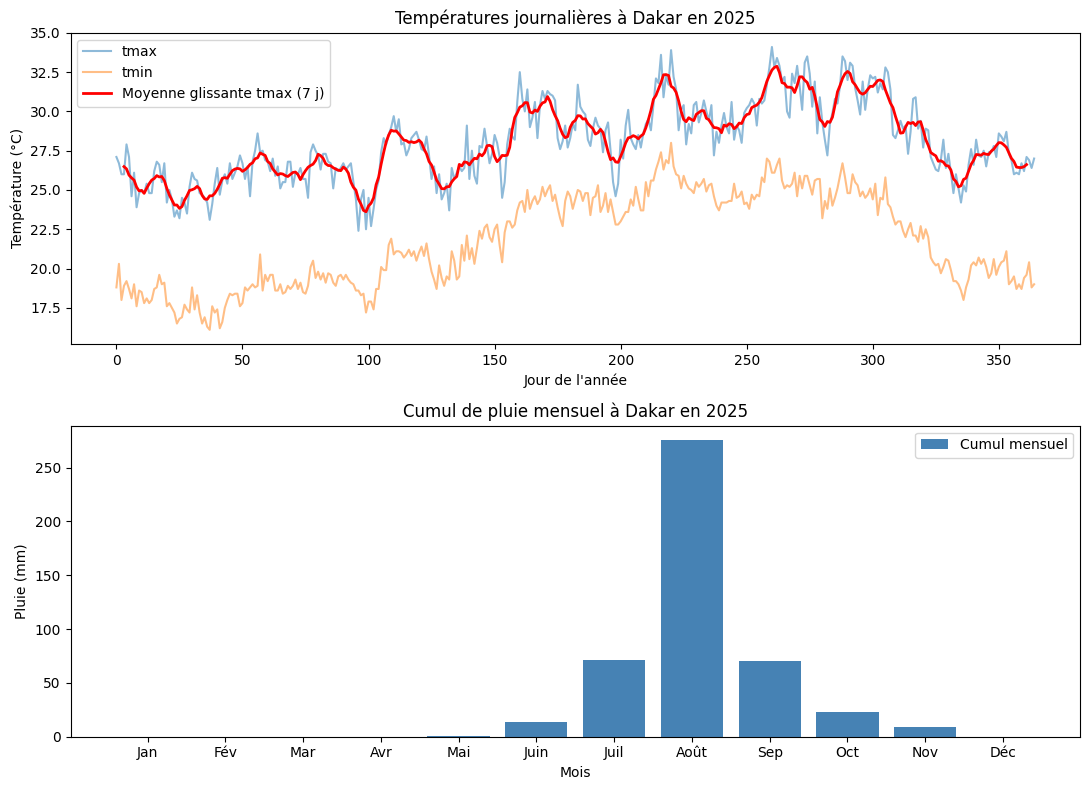

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

x = np.arange(365)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8))

ax1.plot(x, tmax, label="tmax", alpha=0.5)
ax1.plot(x, tmin, label="tmin", alpha=0.5)
ax1.plot(x[3:-3], glissante, label="Moyenne glissante tmax (7 j)", color="red", linewidth=2)
ax1.set_title("Températures journalières à Dakar en 2025")
ax1.set_xlabel("Jour de l'année")
ax1.set_ylabel("Température (°C)")
ax1.legend()

ax2.bar(NOMS_MOIS, cumul, color="steelblue", label="Cumul mensuel")
ax2.set_title("Cumul de pluie mensuel à Dakar en 2025")
ax2.set_xlabel("Mois")
ax2.set_ylabel("Pluie (mm)")
ax2.legend()

plt.tight_layout()
plt.show()

**Interprétation B.2.** La température suit un cycle annuel avec un pic de juin à octobre, que la moyenne glissante lisse bien. Le diagramme en barres montre que la pluie est quasi nulle sauf de juin à octobre, avec un maximum net en août.

In [ ]:
!pip freeze > requirements.txt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')